In [38]:
# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [39]:
# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


In [40]:
# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

In [41]:
# Load the dataset

df = pd.read_csv("diabetes.csv")

# Display first 5 rows
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [42]:
df.shape

(768, 9)

In [43]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [44]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [45]:
# Checking for missing values
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [46]:
#Checking for duplicated values
df.duplicated().sum()

np.int64(0)

In [47]:
#checking target distribution
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [48]:
#percentage of target distribution
df['Outcome'].value_counts(normalize=True) * 100

Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64

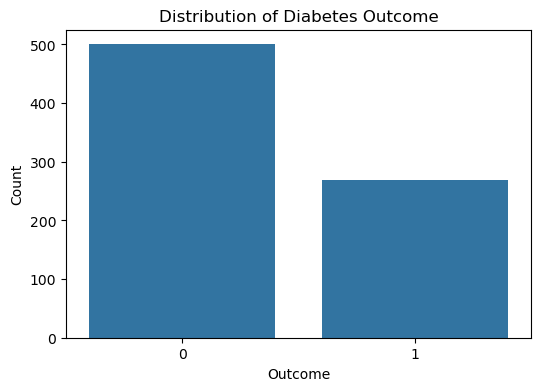

In [49]:
#visualization of distribution (0- no diabetes , 1- diabetes)
plt.figure(figsize=(6, 4))

sns.countplot(x='Outcome', data=df)

plt.title('Distribution of Diabetes Outcome')
plt.xlabel('Outcome')
plt.ylabel('Count')

plt.show()

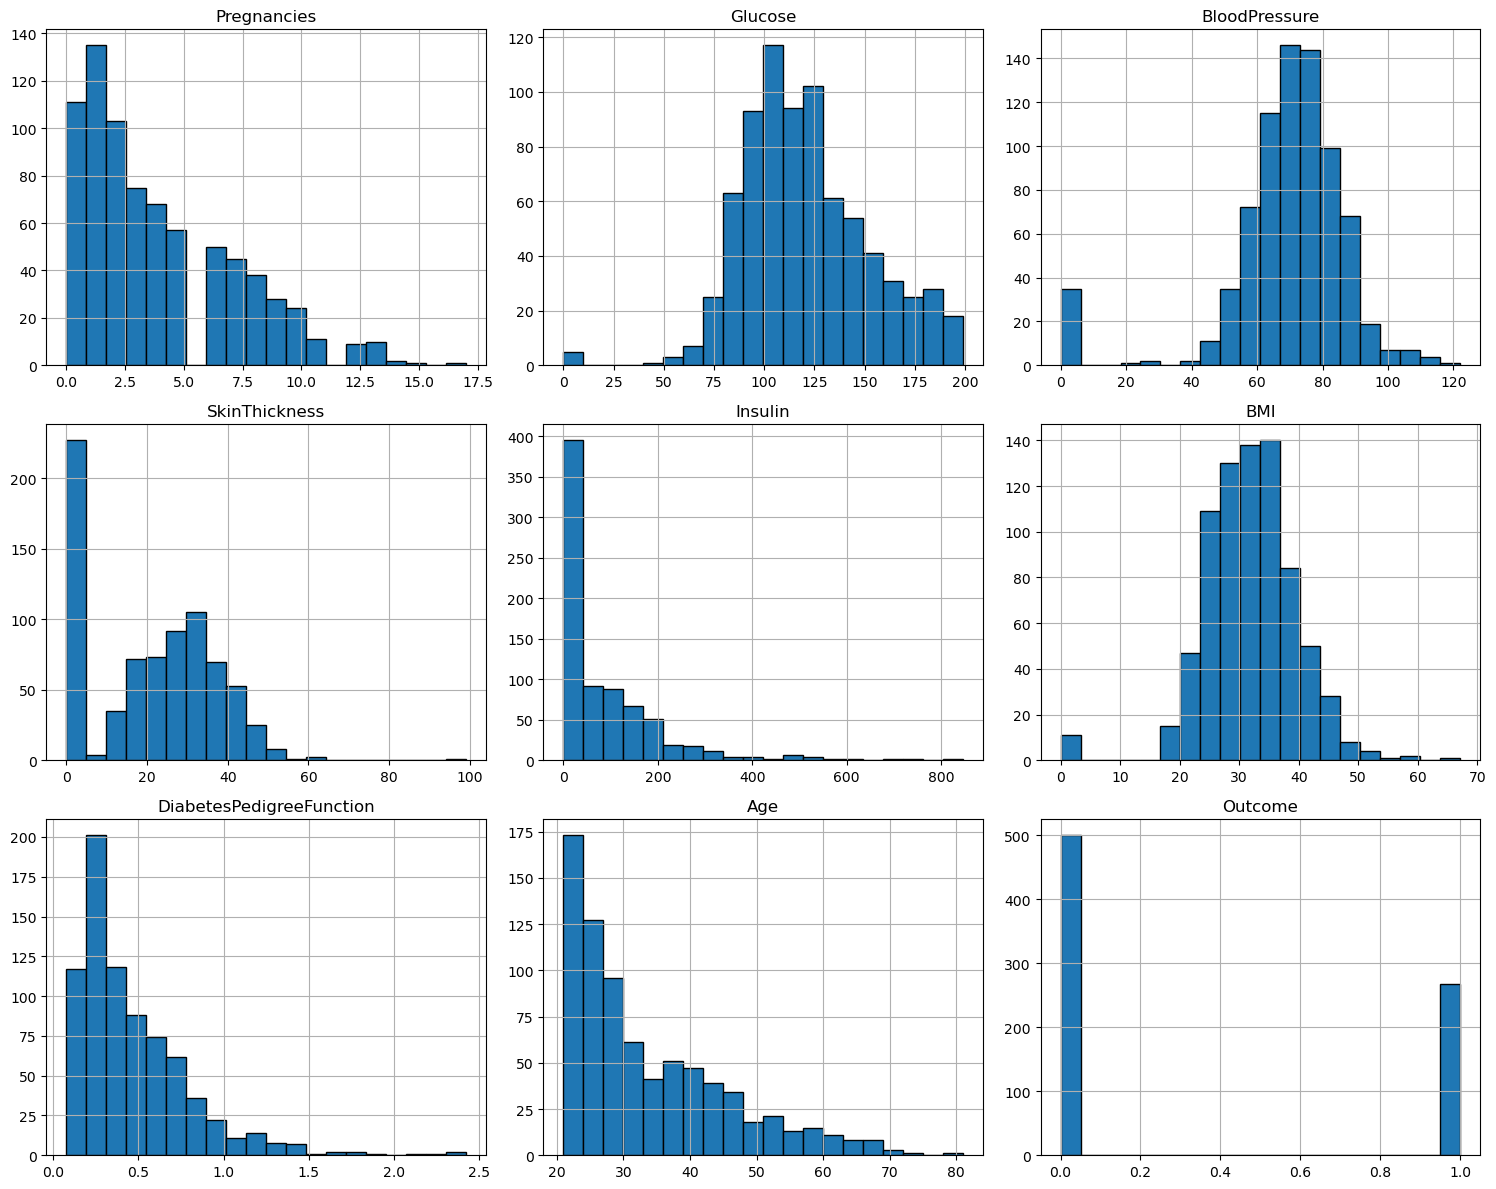

In [50]:
# distribution of numerical features through histogram
df.hist(
    figsize=(15, 12),
    bins=20,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

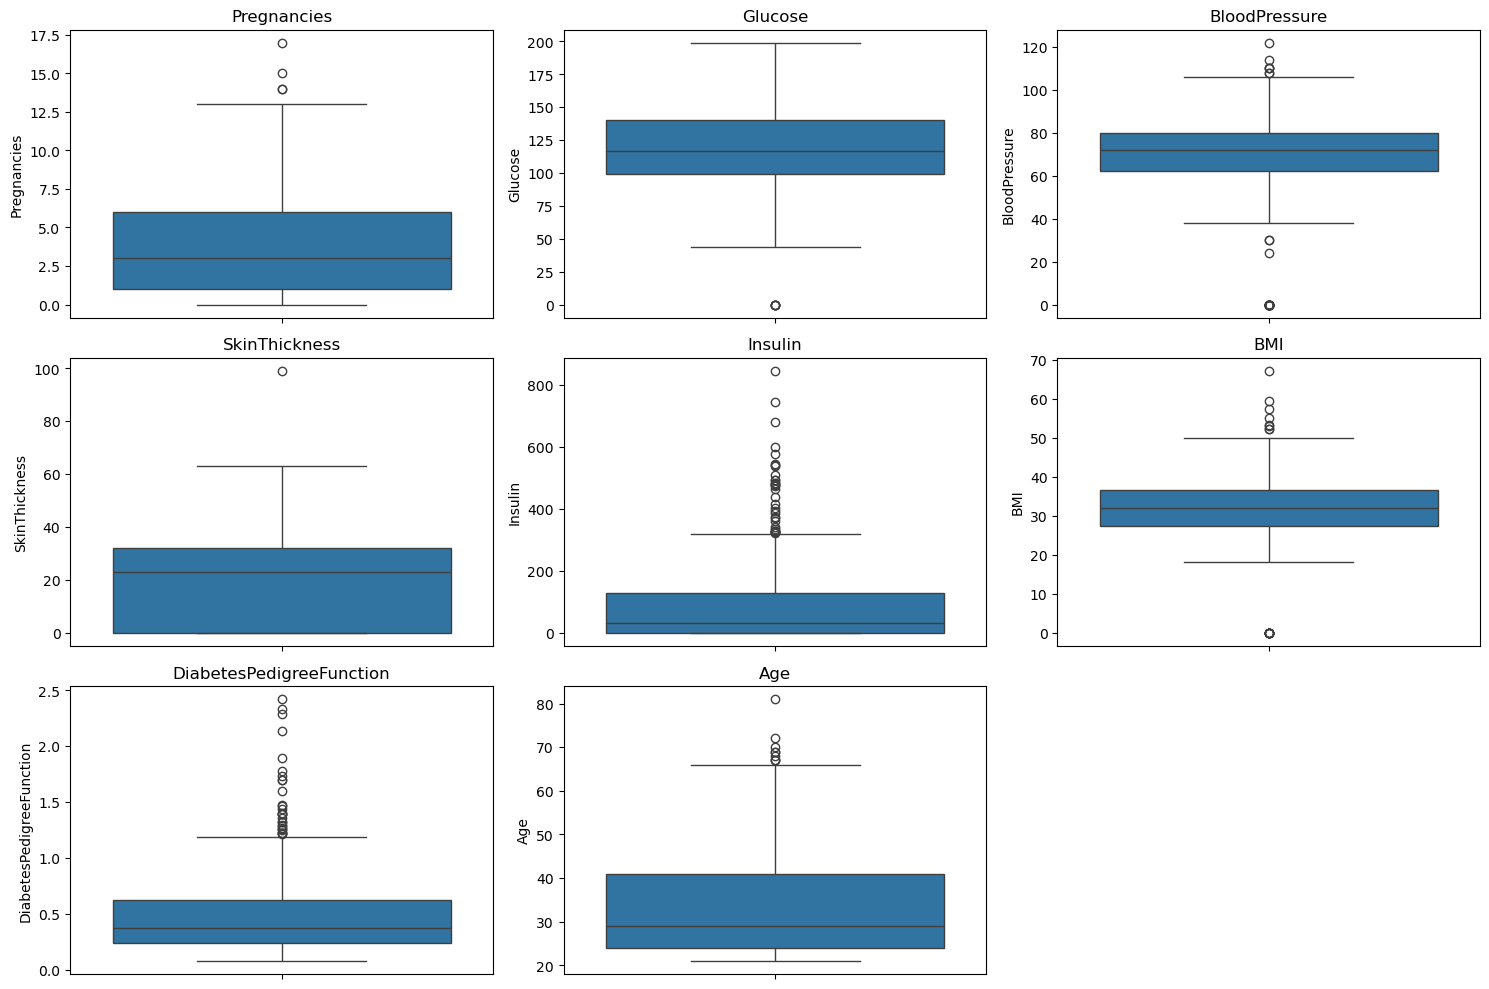

In [51]:
# outlier identification using boxplot
plt.figure(figsize=(15, 10))

for i, column in enumerate(df.columns[:-1], 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

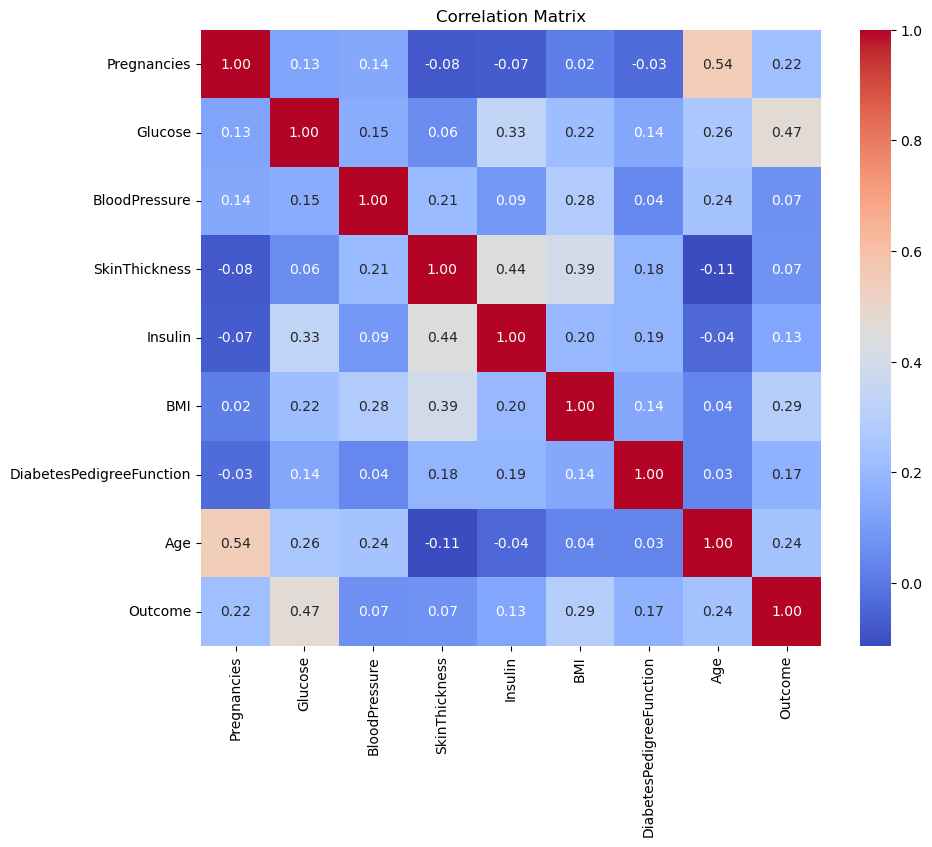

In [52]:
#Correlation matrix
plt.figure(figsize=(10, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()

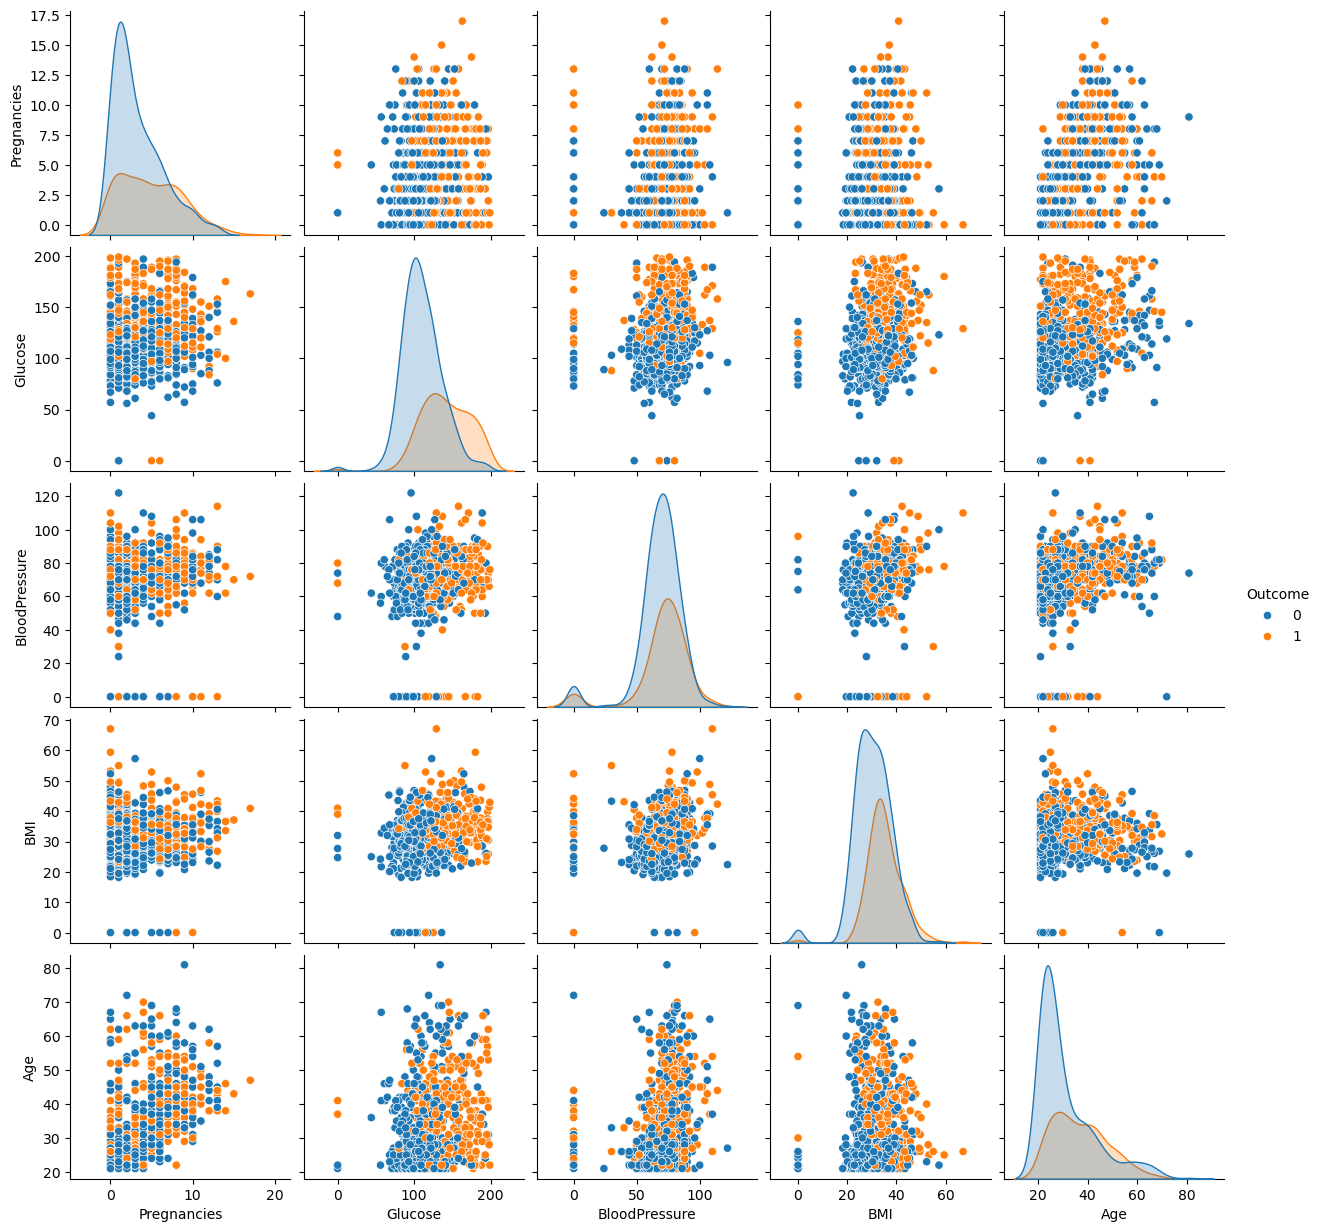

In [53]:
#Pair Plot
sns.pairplot(
    df,
    hue='Outcome',
    vars=[
        'Pregnancies',
        'Glucose',
        'BloodPressure',
        'BMI',
        'Age'
    ]
)

plt.show()

### EDA Summary

The diabetes dataset contains 768 observations and 9 variables, including 8 predictor variables and one binary target variable, Outcome. The target variable represents whether diabetes is present (1) or absent (0). Approximately 34.9% of the observations belong to the positive class, while 65.1% belong to the negative class.

The dataset does not contain explicit null values. However, several variables such as Glucose, BloodPressure, SkinThickness, Insulin, and BMI contain zero values that may represent missing or invalid measurements. These values will be investigated and handled during preprocessing.

Histograms and boxplots show that several variables have skewed distributions and potential outliers, particularly Insulin and DiabetesPedigreeFunction. The correlation analysis indicates that Glucose has a relatively strong positive relationship with the diabetes outcome, while variables such as BMI, Age, Pregnancies, and DiabetesPedigreeFunction also show associations with the target.

These observations suggest that preprocessing and feature scaling will be important before building the Logistic Regression model.

### Handling missing values

#### even though there is no missing values as we checked previously , in a medical dataset a 0 doesnt make sense so we have to fill in that value

In [54]:
# Check zero values in each column

zero_counts = (df == 0).sum()

zero_counts

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [55]:
# Columns where zero represents a missing/invalid measurement
columns_with_zero_as_missing = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]


In [56]:
# Replace 0 with NaN
df[columns_with_zero_as_missing] = df[columns_with_zero_as_missing].replace(0, np.nan)

In [57]:
df.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

#### now we will use median imputation to fill in those missing values

In [58]:
for column in columns_with_zero_as_missing:
    df[column].fillna(df[column].median(), inplace=True)

In [59]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [60]:
## selecting the target and features
# Features
X = df.drop('Outcome', axis=1)

# Target
y = df['Outcome']

In [61]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


### Train-Test split

In [62]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [63]:
#Feature scaling
scaler = StandardScaler()

In [64]:
X_train_scaled = scaler.fit_transform(X_train)

In [65]:
X_test_scaled = scaler.transform(X_test)

In [66]:
# converting scaled data back to dataframe
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

In [67]:
X_train_scaled.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,-0.851355,-1.056427,-0.826740,-1.918187,-1.203361,-0.769477,0.310794,-0.792169
711,0.356576,0.144399,0.477772,-0.229874,-1.470195,-0.417498,-0.116439,0.561034
373,-0.549372,-0.556083,-1.152868,1.233330,-0.555335,0.359790,-0.764862,-0.707594
46,-0.851355,0.811525,-1.315932,-0.004766,-0.161437,-0.402832,0.262314,-0.369293
682,-1.153338,-0.889646,-0.663676,1.120776,-0.415565,1.782373,-0.337630,-0.961320


### Model building

In [68]:
# Create Logistic Regression model

logistic_model = LogisticRegression(random_state=42)

In [70]:
# Train the model

logistic_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [71]:
#checking the model parameters
print("Intercept:")
print(logistic_model.intercept_)

print("\nCoefficients:")
print(logistic_model.coef_)

Intercept:
[-0.87215537]

Coefficients:
[[ 0.37750235  1.18251144 -0.0440658   0.02822519 -0.06615746  0.68873471
   0.23338638  0.14779848]]


In [72]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': logistic_model.coef_[0]
})

coefficients

,Feature,Coefficient
0,Pregnancies,0.377502
1,Glucose,1.182511
2,BloodPressure,-0.044066
3,SkinThickness,0.028225
4,Insulin,-0.066157
5,BMI,0.688735
6,DiabetesPedigreeFunction,0.233386
7,Age,0.147798


In [73]:
# making predictions
y_pred = logistic_model.predict(X_test_scaled)

print(y_pred[:20])

[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0]


In [74]:
# getting prediction probabilities
y_pred_proba = logistic_model.predict_proba(X_test_scaled)

y_pred_proba[:5]

array([[0.39028927, 0.60971073],
       [0.88164424, 0.11835576],
       [0.70653687, 0.29346313],
       [0.7491633 , 0.2508367 ],
       [0.96679333, 0.03320667]])

In [77]:
y_pred_probability = logistic_model.predict_proba(X_test_scaled)[:, 1]

y_pred_probability[:10]

array([0.60971073, 0.11835576, 0.29346313, 0.2508367 , 0.03320667,
       0.16852385, 0.4881643 , 0.92367511, 0.08143405, 0.8385896 ])

In [78]:
# comparing actual vs predicted data
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'Probability': y_pred_probability
})

results.head(10)

,Actual,Predicted,Probability
0,0,1,0.609711
1,0,0,0.118356
2,0,0,0.293463
3,1,0,0.250837
4,0,0,0.033207
5,0,0,0.168524
6,1,0,0.488164
7,1,1,0.923675
8,0,0,0.081434
9,0,1,0.838590


### Model evaluation

In [79]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_pred_probability)

# Display results

print("Logistic Regression Model Evaluation")
print("------------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Logistic Regression Model Evaluation
------------------------------------
Accuracy : 0.7078
Precision: 0.6000
Recall   : 0.5000
F1 Score : 0.5455
ROC-AUC  : 0.8130


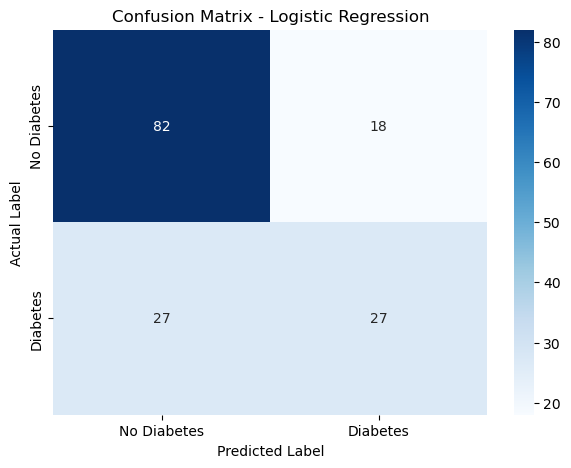

In [80]:
# Generating confusion matrix
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

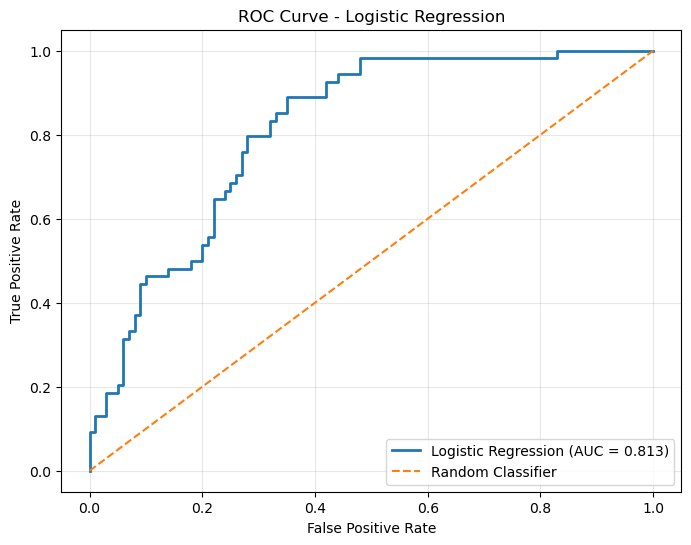

In [81]:
## Plotting ROC curve
# Calculate ROC curve values

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_probability
)

# Calculate ROC-AUC score

roc_auc = roc_auc_score(
    y_test,
    y_pred_probability
)

# Plot ROC curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.3f})',
    linewidth=2
)

# Random classifier reference line

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()

In [82]:
## Final evaluation table
# Create evaluation results DataFrame

evaluation_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],
    'Score': [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

evaluation_results['Score'] = evaluation_results['Score'].round(4)

evaluation_results

,Metric,Score
0,Accuracy,0.7078
1,Precision,0.6000
2,Recall,0.5000
3,F1 Score,0.5455
4,ROC-AUC,0.8130


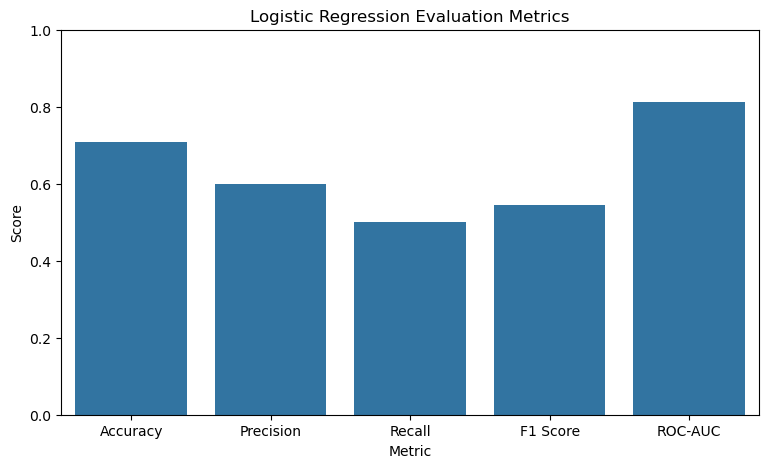

In [83]:
# visualization of the scores
plt.figure(figsize=(9, 5))

sns.barplot(
    data=evaluation_results,
    x='Metric',
    y='Score'
)

plt.title('Logistic Regression Evaluation Metrics')
plt.ylabel('Score')
plt.ylim(0, 1)

plt.show()

### Model Evaluation Summary

The Logistic Regression model was evaluated on the testing dataset using accuracy, precision, recall, F1-score and ROC-AUC. The model achieved an accuracy of **[accuracy]**, precision of **[precision]**, recall of **[recall]**, F1-score of **[F1-score]** and ROC-AUC of **[ROC-AUC]**.

The confusion matrix was used to examine the number of correct and incorrect predictions for each class. Particular attention was given to false negatives, as these represent positive diabetes outcomes that the model failed to identify.

The ROC curve was plotted to evaluate the model's ability to distinguish between the two classes across different classification thresholds. The ROC-AUC score provides a threshold-independent measure of the model's discrimination.

These evaluation metrics provide a more comprehensive understanding of the model's performance than accuracy alone.


### Interpretation

In [84]:
# interpret logistic regression coefficients
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': logistic_model.coef_[0]
})

coefficients

,Feature,Coefficient
0,Pregnancies,0.377502
1,Glucose,1.182511
2,BloodPressure,-0.044066
3,SkinThickness,0.028225
4,Insulin,-0.066157
5,BMI,0.688735
6,DiabetesPedigreeFunction,0.233386
7,Age,0.147798


In [85]:
# Display Logistic Regression coefficients

coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': logistic_model.coef_[0]
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

coefficients

,Feature,Coefficient
1,Glucose,1.182511
5,BMI,0.688735
0,Pregnancies,0.377502
6,DiabetesPedigreeFunction,0.233386
7,Age,0.147798
3,SkinThickness,0.028225
2,BloodPressure,-0.044066
4,Insulin,-0.066157


In [88]:
# Calculate odds ratios

coefficients['Odds_Ratio'] = np.exp(
    coefficients['Coefficient']
)

coefficients

,Feature,Coefficient,Odds_Ratio
1,Glucose,1.182511,3.262558
5,BMI,0.688735,1.991194
0,Pregnancies,0.377502,1.458637
6,DiabetesPedigreeFunction,0.233386,1.262869
7,Age,0.147798,1.159279
3,SkinThickness,0.028225,1.028627
2,BloodPressure,-0.044066,0.956891
4,Insulin,-0.066157,0.935983


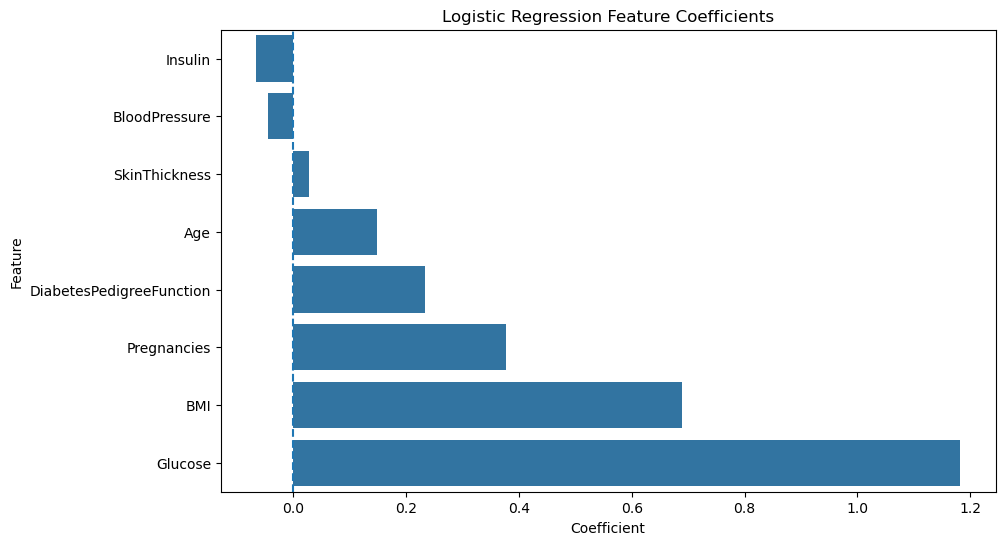

In [89]:
### visualize the coefficients
# Sort coefficients for visualization

coef_plot = coefficients.sort_values(
    by='Coefficient'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=coef_plot,
    x='Coefficient',
    y='Feature'
)

plt.axvline(
    x=0,
    linestyle='--'
)

plt.title('Logistic Regression Feature Coefficients')
plt.xlabel('Coefficient')
plt.ylabel('Feature')

plt.show()

In [91]:
# Rank features by absolute coefficient magnitude

feature_importance = coefficients.copy()

feature_importance['Absolute_Coefficient'] = (
    feature_importance['Coefficient'].abs()
)

feature_importance = feature_importance.sort_values(
    by='Absolute_Coefficient',
    ascending=False
)

feature_importance[
    ['Feature', 'Coefficient', 'Odds_Ratio']
]

,Feature,Coefficient,Odds_Ratio
1,Glucose,1.182511,3.262558
5,BMI,0.688735,1.991194
0,Pregnancies,0.377502,1.458637
6,DiabetesPedigreeFunction,0.233386,1.262869
7,Age,0.147798,1.159279
4,Insulin,-0.066157,0.935983
2,BloodPressure,-0.044066,0.956891
3,SkinThickness,0.028225,1.028627


In [92]:
# Create interpretation table

interpretation = coefficients[
    ['Feature', 'Coefficient', 'Odds_Ratio']
].copy()

interpretation['Direction'] = np.where(
    interpretation['Coefficient'] > 0,
    'Positive',
    'Negative'
)

interpretation

,Feature,Coefficient,Odds_Ratio,Direction
1,Glucose,1.182511,3.262558,Positive
5,BMI,0.688735,1.991194,Positive
0,Pregnancies,0.377502,1.458637,Positive
6,DiabetesPedigreeFunction,0.233386,1.262869,Positive
7,Age,0.147798,1.159279,Positive
3,SkinThickness,0.028225,1.028627,Positive
2,BloodPressure,-0.044066,0.956891,Negative
4,Insulin,-0.066157,0.935983,Negative


## streamlit deployment

In [96]:
import joblib

# Save the trained Logistic Regression model
joblib.dump(logistic_model, 'logistic_regression_model.pkl')

# Save the scaler
joblib.dump(scaler, 'scaler.pkl')

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


### Interview question


### 1. What is the difference between Precision and Recall?

**Precision** measures how many of the observations predicted as positive are actually positive.

**Formula:**

Precision = TP / (TP + FP)

**Recall** measures how many of the actual positive observations were correctly identified by the model.

**Formula:**

Recall = TP / (TP + FN)

In simple terms:

- **Precision:** "When the model predicts positive, how often is it correct?"
- **Recall:** "Of all the actual positive cases, how many did the model identify?"

For diabetes prediction, recall can be particularly important when missing a positive case (false negative) is considered more costly.

### 2. What is Cross-Validation, and why is it important in Binary Classification?

**Cross-validation** is a model evaluation technique in which the training dataset is divided into multiple subsets called folds. The model is trained and validated multiple times, using a different fold for validation each time.

For example, in **5-fold cross-validation**, the dataset is divided into 5 folds. The model is trained five times, with each fold being used as the validation set once while the remaining four folds are used for training.

The validation scores are then averaged to obtain a more reliable estimate of model performance.

Cross-validation is important because:

- It provides a more reliable estimate of model performance.
- It reduces dependence on a single train-validation split.
- It helps identify overfitting.
- It makes better use of the available training data.

For binary classification, **Stratified K-Fold Cross-Validation** is commonly used because it maintains approximately the same proportion of the two target classes in each fold.

In this diabetes dataset, the two classes are:

- **Outcome = 0:** No diabetes
- **Outcome = 1:** Diabetes